# Week 7: Unsupervised Learning — K-Means, Dimensionality Reduction, and PCA

Welcome! In the last few chapters, every dataset came with an answer key: a sale price, a pass/fail label, a transaction that truly needed review. We used those answers to train models and to grade them. But a lot of real-world data has **no answer key at all**. In this chapter we learn to find structure in data without labels. **Which observations naturally belong together? Can we describe our data with fewer features without losing what matters? And how do we judge the results when there are no correct answers to check against?**

---
### What We Will Cover
1. **Why Unsupervised Learning?** — learning without labels, and the two questions it answers
2. **K-Means Clustering** — grouping similar observations, choosing K, and why scaling matters
3. **Dimensionality Reduction** — what a dimension is, and why we might want fewer of them
4. **Principal Component Analysis (PCA)** — building new axes that keep the most information
5. **Using PCA** — a practical workflow, its pitfalls, and combining PCA with K-Means

By the end of this notebook, you will be able to:
* Explain how unsupervised learning differs from supervised learning, and when to use clustering or dimensionality reduction.
* Describe the steps of the K-Means algorithm and fit it with scikit-learn.
* Choose a number of clusters with an elbow plot, and interpret the clusters you find.
* Explain why feature scaling and random starting points can change K-Means results.
* Use PCA to reduce many features to a few, and measure how much information is kept with explained variance.
* Combine PCA and K-Means to visualize high-dimensional data, and recognize what a 2D plot can hide.

**October 26 · Anirra and Yunseo**

This notebook follows the Week 7 lecture. It introduces the ideas; you do not need to master every derivation or code example in one sitting.

> **Note:** All the code cells in this notebook have already been run, so every plot is visible without
> running anything. Re-run them yourself and try changing the numbers — that's the best way to learn!
> To rerun, use a Python 3 environment with `numpy`, `pandas`, `matplotlib`, `scikit-learn`, and `pillow` installed.

---

## Setup

Run this cell once to load all the tools we need.

In [1]:
# Run me first!
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_wine, make_blobs, make_moons, load_sample_image
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances_argmin
import warnings; warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False})

print("Ready! You can now run other cells without issues!")

Ready! You can now run other cells without issues!


---
# Part 1: Why Unsupervised Learning?

## 1.1 Learning Without Labels 🏷️

In the ML Foundations chapter we split machine learning tasks by **whether the training data includes the correct answers**. Here is a quick review:

| | **Supervised Learning** | **Unsupervised Learning** |
|---|---|---|
| **What we have** | Features `X` **and** a known target `y` | Features `X` only |
| **Goal** | Learn to predict the target | Discover structure without an answer key |
| **Example** | Predicting house prices | Discovering customer segments |
| **How do we grade it?** | Compare predictions to the known answers | No answer key — judge by usefulness, stability, and whether it makes sense |

**Unsupervised learning** discovers structure in data *without* known target labels. Instead of predicting an answer, we explore similarities, patterns, and useful ways of representing the data.

> **Everyday analogy:** Someone hands you a box of 1,000 vacation photos and asks you to sort them into albums.
> Nobody tells you what the albums should be called, or even how many there should be. You have to look
> for similarities yourself: beach photos together, food photos together, group selfies together.

Unlabeled data is everywhere. A gym knows when each member checks in, but nobody has labeled members as "regulars" or "weekend warriors." A store has years of purchase histories, but no column called `customer_type`.

## 1.2 Two Questions, Two Techniques

Unsupervised learning usually tries to answer one of two questions:

| Question | Technique | Tool in this chapter |
|---|---|---|
| **Which observations are similar enough to belong together?** | Clustering | **K-Means** (Part 2) |
| **Can we describe observations using fewer features?** | Dimensionality reduction | **PCA** (Parts 3–5) |

Both techniques *simplify* the data, but in different directions. Picture a dataset as a table: clustering simplifies the **rows** by grouping many observations into a handful of clusters, while dimensionality reduction simplifies the **columns** by replacing many features with a few new ones.

> **A word of caution:** Because there is no answer key, there is no accuracy score to tell us whether we did a good job.
> An unsupervised algorithm will *always* hand back some groups or some components, even meaningless ones.
> For every result, ask: **Is it useful? Is it stable? Does it make sense?**

---
# Part 2: K-Means Clustering 🎯

## 2.1 The Main Idea

**K-Means clustering** groups unlabeled data into a chosen number, $K$, of groups called **clusters**. Each cluster is summarized by a single point called its **centroid**, which is the *mean* (average) of all the points in that cluster. That is where the name comes from: $K$ clusters, each represented by a mean.

### Key Vocabulary

| Word | Plain-English Meaning |
|---|---|
| **Cluster** | A group of observations that are similar to each other |
| **Centroid** | The center of a cluster: the average of all of its points |
| **$K$** | The number of clusters. A **hyperparameter** that *you* choose before fitting |
| **Euclidean distance** | Ordinary straight-line distance; how K-Means decides which centroid is "nearest" |
| **Inertia** | The total squared distance from each point to its own centroid. Lower = tighter clusters |

We'll use a fictional dataset about members of a campus gym. For each member, the gym records two numbers: how many times they visit per week, and how long a typical visit lasts. Nobody has labeled the members.

,visits_per_week,hours_per_visit
0,4.500615,0.761726
1,4.649373,0.200000
2,4.362931,0.484208
3,4.054704,0.575678
4,4.272665,0.914254


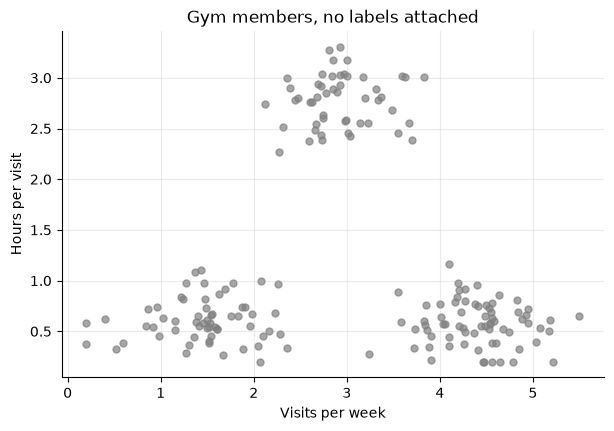

In [2]:
# ── Helper: create fictional gym member data ────────────────────────────────
def making_data_for_gym():
    """
    Returns a DataFrame of 180 fictional gym members with two features:
      - visits_per_week: how many times the member visits each week (0.2 to 7)
      - hours_per_visit: how long a typical visit lasts, in hours
    The members secretly come from 3 groups with different habits, but the data has no labels.
    """
    rng = np.random.default_rng(7)
    groups = [(4.5, 0.6, 70),   # (average visits, average hours, number of members)
              (3.0, 2.8, 50),
              (1.5, 0.6, 60)]
    visits, hours = [], []
    for avg_visits, avg_hours, n in groups:
        visits.append(np.clip(rng.normal(avg_visits, 0.5, n), 0.2, 7))
        hours.append(np.clip(rng.normal(avg_hours, 0.25, n), 0.2, None))
    return pd.DataFrame({'visits_per_week': np.concatenate(visits),
                         'hours_per_visit': np.concatenate(hours)})

gym = making_data_for_gym()
display(gym.head())

plt.figure(figsize=(7, 4.5))
plt.scatter(gym['visits_per_week'], gym['hours_per_visit'], color='gray', alpha=0.7, s=25)
plt.xlabel('Visits per week'); plt.ylabel('Hours per visit')
plt.title('Gym members, no labels attached')
plt.show()

Do you see groups? Most people spot three almost instantly: long workouts at the top, and two groups of short workouts at the bottom, one visiting often and one only occasionally. Your brain just did clustering! Can a computer find the same groups on its own?

## 2.2 The K-Means Algorithm, Step by Step

K-Means (also called **Lloyd's algorithm**) repeats two simple steps until nothing changes:

```
1. Choose K                  →  the number of clusters (you decide!)
2. Initialize K centroids    →  usually random starting points
3. Assign                    →  each point joins its NEAREST centroid
4. Update                    →  each centroid moves to the MEAN of its points
5. Repeat steps 3 and 4      →  until the assignments stop changing
```

<div align="center"><b>Choose K → Assign points → Update centroids → Repeat</b></div>

### What does "nearest" mean?

K-Means uses the **Euclidean distance**, the straight-line distance you learned in geometry. For a point $x$ and a centroid $c$ with $p$ features:

$$\text{distance}(x, c) = \sqrt{(x_1 - c_1)^2 + (x_2 - c_2)^2 + \cdots + (x_p - c_p)^2}$$

**Worked example:** A member visits 4 times per week for 0.9 hours. Centroid A is at (4.5, 0.6) and centroid B is at (3.0, 2.8).

* Distance to A $= \sqrt{(4-4.5)^2 + (0.9-0.6)^2} = \sqrt{0.25 + 0.09} \approx 0.58$
* Distance to B $= \sqrt{(4-3.0)^2 + (0.9-2.8)^2} = \sqrt{1 + 3.61} \approx 2.15$

Centroid A is much closer, so this member joins cluster A.

### What does "update" mean?

Each centroid moves to the **mean** of the points assigned to it, one feature at a time. If cluster A contained members at (5.0, 0.8), (6.0, 1.0), and (7.0, 1.5), its new centroid would be $\left(\frac{5+6+7}{3}, \frac{0.8+1.0+1.5}{3}\right) = (6.0, 1.1)$.

### Watching it run

Let's watch K-Means with $K = 3$ on the gym data. To make it interesting, we start the three centroids (the black **X** marks) in deliberately bad spots. We use scikit-learn's `pairwise_distances_argmin` to find each point's nearest centroid, and pandas' `groupby` to take the means.

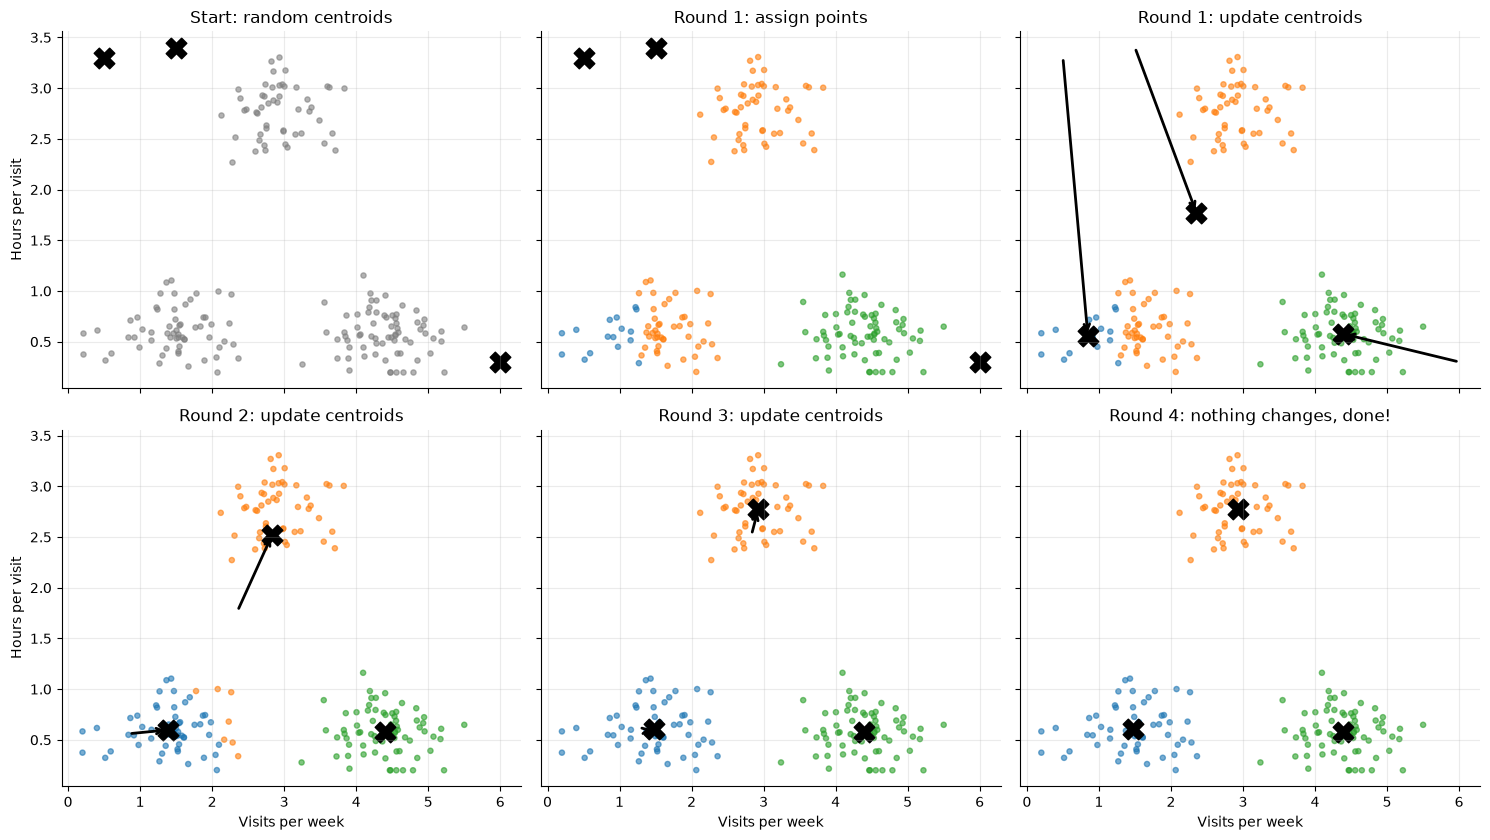

K-Means converged after 3 rounds of updates.


In [3]:
points = gym[['visits_per_week', 'hours_per_visit']].to_numpy()
centroids = np.array([[0.5, 3.3], [1.5, 3.4], [6.0, 0.3]])   # deliberately bad starting spots
colors = np.array(['tab:blue', 'tab:orange', 'tab:green'])

def draw(ax, labels, centers, title, old_centers=None):
    point_colors = 'gray' if labels is None else colors[labels]
    ax.scatter(points[:, 0], points[:, 1], c=point_colors, s=14, alpha=0.6)
    if old_centers is not None:   # arrows show how far each centroid moved
        for old, new in zip(old_centers, centers):
            ax.annotate('', xy=new, xytext=old, arrowprops=dict(arrowstyle='->', lw=2))
    ax.scatter(centers[:, 0], centers[:, 1], marker='X', s=220, color='black')
    ax.set_title(title)

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharex=True, sharey=True)
axes = axes.flatten()
draw(axes[0], None, centroids, 'Start: random centroids')

rnd = 0
while True:
    rnd += 1
    labels = pairwise_distances_argmin(points, centroids)                 # ASSIGN step
    new_centroids = gym.groupby(labels)[['visits_per_week', 'hours_per_visit']].mean().to_numpy()   # UPDATE step
    if rnd == 1:
        draw(axes[1], labels, centroids, 'Round 1: assign points')
    if rnd <= 3:
        draw(axes[rnd + 1], labels, new_centroids, f'Round {rnd}: update centroids', old_centers=centroids)
    if np.allclose(new_centroids, centroids):
        break
    centroids = new_centroids

draw(axes[5], labels, centroids, f'Round {rnd}: nothing changes, done!')
for ax in axes[3:]:
    ax.set_xlabel('Visits per week')
for ax in axes[::3]:
    ax.set_ylabel('Hours per visit')
plt.tight_layout()
plt.show()
print(f"K-Means converged after {rnd - 1} rounds of updates.")

Panel by panel:

* **Start:** Two centroids begin crammed together in the top left, and one sits far off in the bottom right.
* **Round 1:** Every member joins the closest centroid. The bottom-right centroid claims the quick regulars, but one of the top-left centroids claims both the long-session lifters *and* most of the occasional drop-ins. When it moves to the average of its members, it lands in the empty space between those two groups.
* **Rounds 2–3:** Members switch clusters as the centroids move. The stranded centroid climbs into the long-session group, while the other top-left centroid takes over the drop-ins.
* **Done:** Assigning again changes nothing, so the algorithm stops. We say K-Means has **converged**.

Even from a bad start, K-Means found the three groups in just a few rounds.

## 2.3 K-Means in scikit-learn

In practice, scikit-learn's `KMeans` runs the whole loop for us:

visits_per_week       hours_per_visit      
                   mean count            mean count
cluster                                            
0                  4.39    70            0.58    70
1                  1.47    60            0.61    60
2                  2.93    50            2.78    50

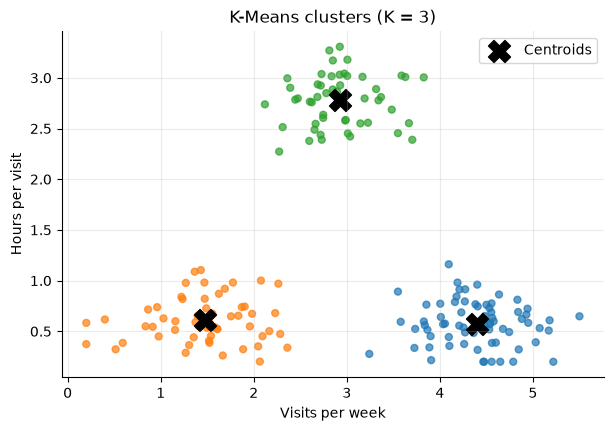

In [4]:
kmeans = KMeans(
    n_clusters=3,    # K: we want 3 groups
    n_init=10,       # run the algorithm from 10 random starts, keep the best (see 2.5)
    random_state=42  # fixes the randomness for reproducibility
)
kmeans.fit(gym)      # no y! unsupervised models only get the features

gym['cluster'] = kmeans.labels_          # the cluster each member was assigned to
display(gym.groupby('cluster').agg(['mean', 'count']).round(2))

plt.figure(figsize=(7, 4.5))
plt.scatter(gym['visits_per_week'], gym['hours_per_visit'], c=gym['cluster'], cmap='tab10', vmax=9, s=25, alpha=0.7)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker='X', s=250, color='black', label='Centroids')
plt.xlabel('Visits per week'); plt.ylabel('Hours per visit')
plt.title('K-Means clusters (K = 3)'); plt.legend()
plt.show()

The summary table is how we **interpret** the clusters. Reading the averages, we might name them:

* **Quick regulars:** about 4.5 visits per week, about 35 minutes each.
* **Long-session lifters:** about 3 visits per week, but almost 3 hours each.
* **Occasional drop-ins:** about 1.5 visits per week, about 35 minutes each.

> **The cluster numbers mean nothing on their own.** K-Means could just as easily have numbered the three
> clusters in a different order. The numbers are name tags; giving clusters real-world meaning is *our* job.

## 2.4 Choosing the Number of Clusters

$K$ is a decision we make *before* fitting, and K-Means will happily find however many clusters we ask for, whether or not they really exist.

* **Too small:** distinct groups get merged together.
* **Too large:** meaningful groups get split into pieces.

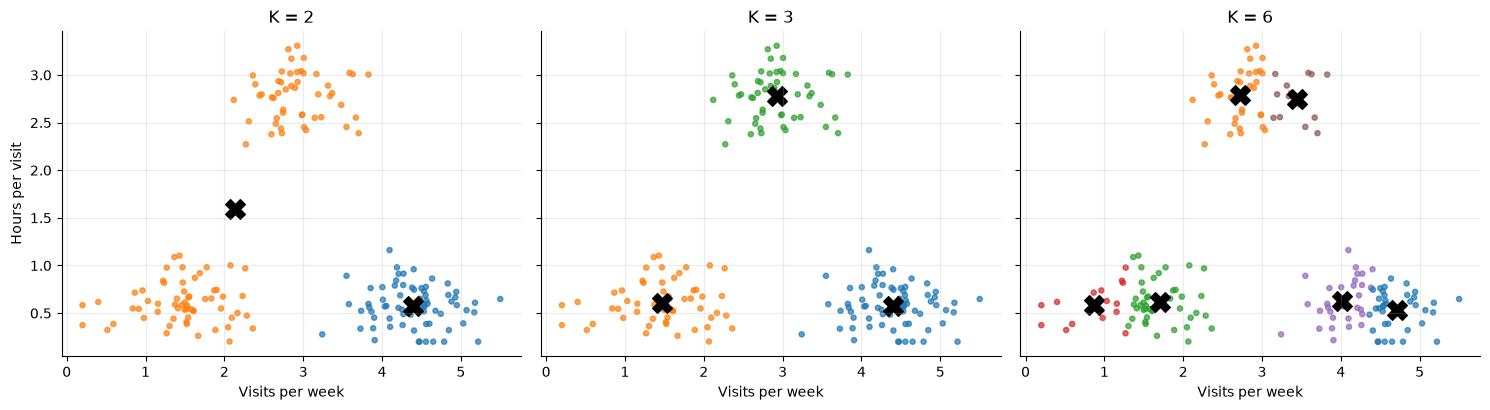

In [5]:
features = gym[['visits_per_week', 'hours_per_visit']]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, k in zip(axes, [2, 3, 6]):
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(features)
    ax.scatter(features['visits_per_week'], features['hours_per_visit'], c=model.labels_, cmap='tab10', vmax=9, s=14, alpha=0.7)
    ax.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], marker='X', s=200, color='black')
    ax.set_title(f'K = {k}'); ax.set_xlabel('Visits per week')
axes[0].set_ylabel('Hours per visit')
plt.tight_layout()
plt.show()

With $K = 2$, two real groups are forced into one cluster. With $K = 6$, natural groups get chopped into slices that don't mean much.

### The Elbow Method

To compare values of $K$ with a number, we use **inertia**: the sum of squared distances from each point to its own centroid.

$$\text{inertia} = \sum_{\text{all points } x} \text{distance}(x, \text{its centroid})^2$$

Lower inertia means tighter clusters, so why not pick the $K$ with the lowest inertia? Because inertia **always** goes down as $K$ grows. If every point got its own cluster, the inertia would be exactly 0: a perfect score for a useless result!

Instead, we plot inertia for several values of $K$ and look for the **elbow**: the point where adding another cluster stops helping much.

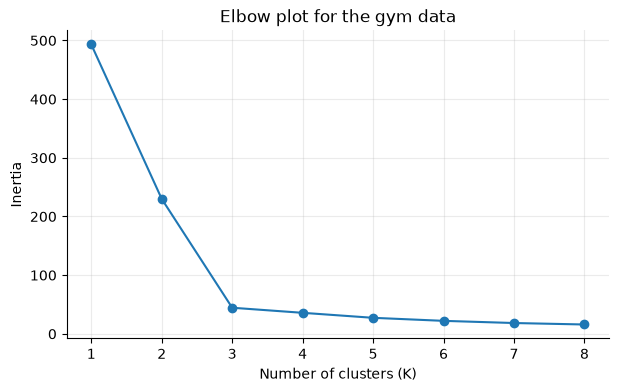

In [6]:
ks = range(1, 9)
inertias = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(features)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(ks, inertias, 'o-')
plt.xlabel('Number of clusters (K)'); plt.ylabel('Inertia')
plt.title('Elbow plot for the gym data')
plt.show()

Inertia drops sharply from $K = 1$ to $K = 3$, then flattens out. The elbow is at **$K = 3$**, matching what we saw by eye.

The elbow method is a guide, not a strict rule. Sometimes the curve bends so gradually that there is no clear elbow. In practice, **compare a few reasonable values of $K$ and interpret the resulting clusters**. The best $K$ gives you groups that are useful for your question.

> **Knowledge check: Which K?** A customer dataset appears to have three compact, well-separated groups.
> Would you start with $K = 2$, $K = 3$, or $K = 10$? What might go wrong with the other choices?

<details>
<summary><b>Click for a sample answer</b></summary>

Start with **$K = 3$**, since it matches the visible structure. With $K = 2$, two real groups would be merged, hiding a real difference between customers. With $K = 10$, real groups would be split into small "segments" that differ only because of random noise. Either way, still check the elbow plot and the cluster summaries before trusting the result.
</details>

## 2.5 Different Starts, Different Answers

K-Means begins from *random* centroids, so it **may not return the same groupings every time**. Usually different starts end in the same place, but sometimes the algorithm gets stuck in a poor solution it can't escape. Here are two single runs with $K = 4$ on the same made-up data; the only difference is the random start:

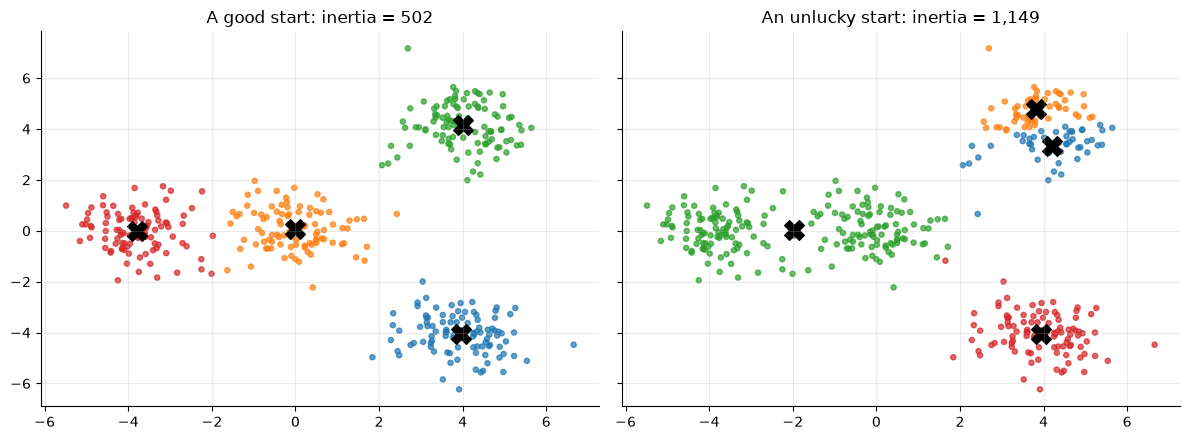

In [7]:
# ── Helper: create 4 well-separated blobs ───────────────────────────────────
def making_data_for_starts():
    """Returns 400 points in 2-D that form 4 clear groups."""
    X, _ = make_blobs(n_samples=400, centers=[[-4, 0], [0, 0], [4, 4], [4, -4]],
                      cluster_std=0.8, random_state=1)
    return X

blobs = making_data_for_starts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, seed, title in zip(axes, [2, 0], ['A good start', 'An unlucky start']):
    model = KMeans(n_clusters=4, init='random', n_init=1, random_state=seed).fit(blobs)   # ONE random start
    ax.scatter(blobs[:, 0], blobs[:, 1], c=model.labels_, cmap='tab10', vmax=9, s=14, alpha=0.7)
    ax.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], marker='X', s=200, color='black')
    ax.set_title(f'{title}: inertia = {model.inertia_:,.0f}')
plt.tight_layout()
plt.show()

On the right, two centroids ended up sharing one group while a single centroid got stuck between two others. Its inertia is more than twice as high, which tells us it is a worse solution.

This is why `n_init` exists. With `n_init=10`, scikit-learn runs K-Means from 10 different starts and keeps the one with the **lowest inertia**. By default it also uses a smarter starting rule called **k-means++**, which spreads the first centroids apart and makes unlucky starts rarer.

## 2.6 Why Feature Scaling Matters ⚖️

K-Means is built on distances. In the gym data, both features happen to have similar ranges (a few visits, a few hours). But **if one feature is measured in thousands and another from 0 to 1, the large one dominates every distance**.

To see how badly this can go, let's use a real dataset: chemical measurements of **178 Italian wines** made from **three different grape varieties**, available in scikit-learn as `load_wine`. The dataset includes the true variety, but **we will hide it from K-Means** and only use it at the end to check our work. (In a real unsupervised problem, you wouldn't get to peek!)

In [8]:
wine = load_wine(as_frame=True)
wine_X = wine.data                 # 13 chemical measurements
wine_variety = wine.target         # the true grape variety (0, 1, or 2). Hidden from K-Means!

display(wine_X.describe().loc[['mean', 'std', 'min', 'max']].round(2))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


Look at the scales: `hue` ranges from about 0.5 to 1.7, while `proline` (an amino acid) ranges from about 280 to 1,680. In a distance calculation, proline drowns out almost everything else.

Let's cluster with $K = 3$ and use `pd.crosstab` to count how many wines of each true variety landed in each cluster:

In [9]:
kmeans_raw = KMeans(n_clusters=3, n_init=10, random_state=42).fit(wine_X)
display(pd.crosstab(wine_variety, kmeans_raw.labels_, rownames=['True variety'], colnames=['Cluster (raw features)']))

Cluster (raw features),0,1,2
True variety,,,
0,13,46,0
1,20,1,50
2,29,0,19


That's a mess: every cluster mixes varieties. The clusters are mostly just "low proline," "medium proline," and "high proline."

The fix is **standardization**: convert each feature to standard units by subtracting its mean and dividing by its standard deviation,

$$z = \frac{x - \text{mean}}{\text{standard deviation}}$$

so that every feature has mean 0 and standard deviation 1 and gets an equal say in the distance. As in the Model Evaluation chapter, we put the scaler and the model together in a **pipeline**:

In [10]:
kmeans_scaled = make_pipeline(StandardScaler(), KMeans(n_clusters=3, n_init=10, random_state=42))
kmeans_scaled.fit(wine_X)
scaled_labels = kmeans_scaled[-1].labels_    # the KMeans step is the last step of the pipeline

display(pd.crosstab(wine_variety, scaled_labels, rownames=['True variety'], colnames=['Cluster (standardized)']))

Cluster (standardized),0,1,2
True variety,,,
0,0,0,59
1,65,3,3
2,0,48,0


What a difference! Each cluster now lines up with one grape variety, and only 6 of the 178 wines land in a cluster dominated by a different variety. K-Means rediscovered the three varieties from chemistry alone, without ever seeing the labels.

> **Think carefully about whether scaling is appropriate.** Standardizing makes sense when features use different units
> (minutes vs. counts, grams vs. dollars). If every feature already shares one unit and the differences in spread are
> meaningful (for example, hours per week spent on different activities), standardizing could erase useful information.
> Always ask what a "distance" between two observations *should* mean for your problem.

## 2.7 K-Means Limitations

K-Means always draws **straight-line boundaries** between clusters, because each point simply joins its nearest centroid. Groups with unusual shapes confuse it:

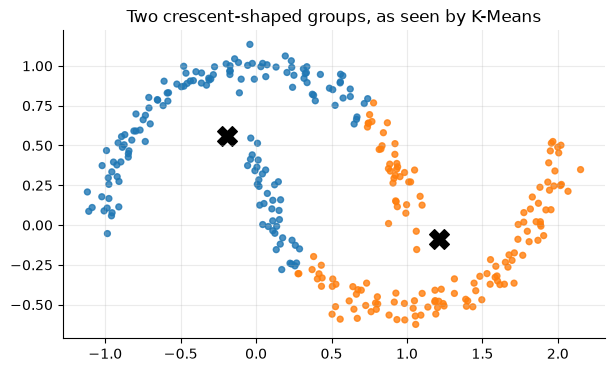

In [11]:
moons, _ = make_moons(n_samples=300, noise=0.06, random_state=0)
moon_model = KMeans(n_clusters=2, n_init=10, random_state=42).fit(moons)

plt.figure(figsize=(7, 4))
plt.scatter(moons[:, 0], moons[:, 1], c=moon_model.labels_, cmap='tab10', vmax=9, s=18, alpha=0.8)
plt.scatter(moon_model.cluster_centers_[:, 0], moon_model.cluster_centers_[:, 1], marker='X', s=200, color='black')
plt.title('Two crescent-shaped groups, as seen by K-Means')
plt.show()

Our eyes see two crescents; K-Means slices them with a straight line. Other clustering methods (such as DBSCAN or hierarchical clustering) handle shapes like this better.

### Pros & Cons — K-Means

| Strengths | Weaknesses |
|-----------|------------|
| Simple, fast, and easy to explain | You must choose $K$ in advance |
| Scales to large datasets | Results depend on the random start (use `n_init`) |
| Centroids give an easy-to-read summary of each group | Works best on compact, roughly round clusters of similar size |
| A great first look at a new dataset | Outliers pull centroids away from typical points, since a centroid is a mean |
| | Sensitive to feature scales; usually standardize first |
| | Cluster labels have no built-in real-world meaning |

### Key Parameters — K-Means

| Parameter | What it does | Default | Effect of changing it |
|-----------|-------------|---------|----------------------|
| `n_clusters` | $K$, the number of clusters | `8` | Too few merges real groups; too many splits them. Choose with the elbow method + interpretation |
| `n_init` | How many random starts to try, keeping the lowest inertia | `'auto'` | Higher = more reliable but slower. `10` is a common choice |
| `init` | How starting centroids are chosen | `'k-means++'` | `'random'` picks plain random starts, which get stuck more often |
| `random_state` | Fixes the randomness | `None` | Any integer makes results reproducible |

## 2.8 K-Means in Real Projects

Common uses include **customer segmentation**, **exploratory grouping** of a new dataset, and **color quantization** (image compression). That last one is a fun example: every pixel of a color image is three numbers (red, green, blue), so each pixel is a point in 3-D space. If we cluster the pixels with $K = 8$, each centroid is one "average color," and we can redraw the image using only those 8 colors.

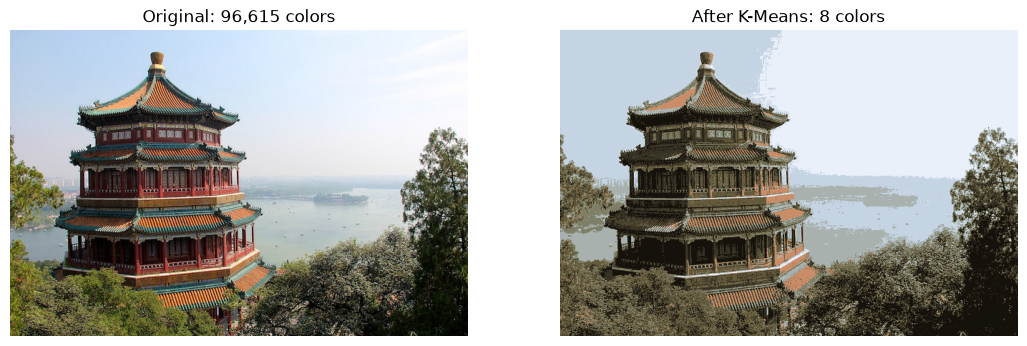

In [12]:
image = load_sample_image('china.jpg')        # a photo that ships with scikit-learn
pixels = image.reshape(-1, 3) / 255           # one row per pixel; columns = red, green, blue

sample = pixels[np.random.default_rng(0).choice(len(pixels), 5000, replace=False)]   # fit on a sample for speed
color_model = KMeans(n_clusters=8, n_init=10, random_state=42).fit(sample)
compressed = color_model.cluster_centers_[color_model.predict(pixels)].reshape(image.shape)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].imshow(image); axes[0].set_title(f'Original: {len(np.unique(pixels, axis=0)):,} colors')
axes[1].imshow(compressed); axes[1].set_title('After K-Means: 8 colors')
for ax in axes:
    ax.axis('off')
plt.show()

Instead of storing three color values for each of the ~270,000 pixels, we only need the 8 centroid colors plus one small number (0–7) per pixel.

Whatever the application, the same habits apply: **always inspect your clusters** and compare their feature summaries, and **ask whether the results are useful and stable**. Would a business actually treat each segment differently? Do you get similar clusters from a different random start or a slightly different sample?

### ✏️ Quick Check

1. After one round of K-Means, a centroid has three points assigned to it: (1, 2), (3, 2), and (2, 5). Where does the centroid move?
2. Your elbow plot keeps going down all the way to $K = 20$. Does that mean $K = 20$ is best?
3. You cluster customers using `annual_income` (in dollars) and `visits_per_month`. Without scaling, which feature will mostly decide the clusters, and why?

<details>
<summary><b>Click for answers</b></summary>

1. To the mean of the three points: $\left(\frac{1+3+2}{3}, \frac{2+2+5}{3}\right) = (2, 3)$.
2. **No.** Inertia always decreases as $K$ grows. Look for the elbow where the improvement slows down, and check whether the clusters are interpretable.
3. **`annual_income`.** Differences in income are thousands of dollars while differences in visits are a few visits, so income dominates every distance. Standardize first.
</details>

---
# Part 3: Dimensionality Reduction 📉

K-Means grouped the 178 wines using 13 measurements, but we never got to *see* those clusters. Our eyes are great with 2-D scatter plots and give up quickly after that. What can we do when a dataset has dozens of features?

## 3.1 What Is a Dimension?

Each feature (column) defines one **dimension** of the **feature space**, and every row is a single point in that space.

* **Height** alone: each person is a point on a number line (1 dimension).
* **Height and weight**: each person is a point on a scatter plot (2 dimensions).
* Add **age, income, and spending habits**, and each person is a point in 5 dimensions.
* A dataset with 100 numeric features lives in a 100-dimensional space.

Each wine is a point in 13-dimensional space. We can draw three of those dimensions at once, and that's about the limit:

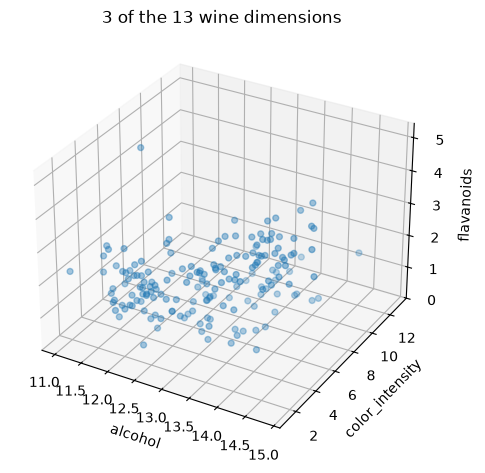

In [13]:
fig = plt.figure(figsize=(7.5, 5.5))
ax = fig.add_subplot(projection='3d')
ax.scatter(wine_X['alcohol'], wine_X['color_intensity'], wine_X['flavanoids'], s=18, alpha=0.7)
ax.set_xlabel('alcohol'); ax.set_ylabel('color_intensity'); ax.set_zlabel('flavanoids')
ax.set_title('3 of the 13 wine dimensions')
plt.show()

## 3.2 Why Reduce Dimensions?

**Dimensionality reduction** means representing data with fewer features than we started with. There are four main reasons to want this:

1. **Humans cannot directly visualize dozens of dimensions.** Even plotting every *pair* of the 13 wine features would take $\binom{13}{2} = 78$ scatter plots.
2. **Some features carry overlapping information.** Many features move together, as the next plot shows.
3. **Fewer features can simplify visualization and downstream modeling.** Models with fewer, less redundant inputs are often faster and easier to understand.
4. **We want a compact representation without losing too much useful information.** That is the real goal.

Here are two wine measurements, total phenols and flavanoids (flavanoids are a type of phenol, so it makes sense that they are related):

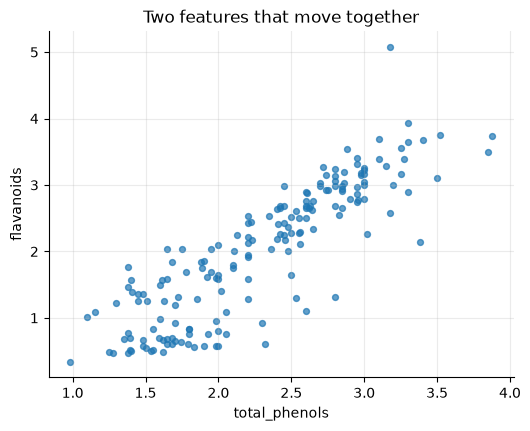

Correlation: 0.86


In [14]:
plt.figure(figsize=(6, 4.5))
plt.scatter(wine_X['total_phenols'], wine_X['flavanoids'], s=18, alpha=0.7)
plt.xlabel('total_phenols'); plt.ylabel('flavanoids')
plt.title('Two features that move together')
plt.show()

print(f"Correlation: {wine_X['total_phenols'].corr(wine_X['flavanoids']):.2f}")

With a correlation of about 0.86, knowing a wine's total phenols already tells you a lot about its flavanoids. Keeping both columns doesn't give us twice the information; much of it is repeated.

## 3.3 The Central Tradeoff

Dimensionality reduction compresses a dataset into fewer coordinates. Lower-dimensional data is easier to plot and may be faster to process, **but compression can discard information.**

<div align="center"><b>Fewer dimensions ↔ Less detail retained</b></div>

> **Everyday analogy:** A BART map throws away real distances, street names, and the actual shape of the tracks.
> Yet it is *more* useful than a satellite photo for figuring out where to transfer trains, because it keeps exactly
> the information that matters for that task.

**The goal is to keep what matters for our task**, not to keep everything.

## 3.4 Selection vs. Extraction

There are two broad ways to end up with fewer features:

| | **Feature Selection** | **Feature Extraction** |
|---|---|---|
| **What it does** | Keeps a subset of the original columns | Builds new columns out of the original columns |
| **Wine example** | Keep only `alcohol` and `proline` | Combine the three phenol measurements into one "phenol score" |
| **Interpretation** | Easy: columns mean what they always meant | Harder: each new column is a mix of old ones |
| **What's lost** | Everything in the dropped columns | Whatever the combination doesn't capture |

You saw feature selection in the Feature Engineering chapter. Here is a hand-made feature extraction: average three related features in standard units.

In [15]:
phenol_cols = ['total_phenols', 'flavanoids', 'proanthocyanins']
phenols_z = (wine_X[phenol_cols] - wine_X[phenol_cols].mean()) / wine_X[phenol_cols].std()

wine_extracted = pd.DataFrame({'phenol_score': phenols_z.mean(axis=1)})   # 3 columns -> 1 column
display(wine_extracted.head())

,phenol_score
0,1.020023
1,0.251808
2,1.382932
3,1.658696
4,0.622827


Three columns became one, and that one column still carries information from all three. But we chose *which* columns to combine and *how* to weight them by hand. What if the data could decide which combinations capture the most information? That is exactly what **PCA** does. PCA is a feature extraction method: **a principal component is not usually a single original column**, but a combination of them.

### ✏️ Quick Check

1. A dataset has 40 numeric columns. How many dimensions does its feature space have?
2. Is keeping only the 5 columns with the highest correlation to a target feature selection or feature extraction?
3. Why might two highly correlated features be a good candidate for combining into one?

<details>
<summary><b>Click for answers</b></summary>

1. **40.** Each numeric feature is one dimension.
2. **Feature selection.** We keep a subset of the original columns without changing them.
3. They carry **overlapping information**: knowing one mostly tells you the other. One combined feature keeps most of what both say.
</details>

---
# Part 4: Principal Component Analysis (PCA) 🧭

## 4.1 The Main Idea

**Principal Component Analysis (PCA)** finds new axes, called **principal components**, that capture the **variance** (spread) in the data:

* **PC1** points in the direction where the data is most spread out. It captures the greatest possible variance.
* **PC2** captures as much of the *remaining* variance as possible, in a direction **orthogonal** (at a right angle) to PC1.
* PC3, PC4, ... continue the pattern, each at right angles to all previous ones.
* Each component is a **weighted mix** of the original features.

With 13 features, PCA can build up to 13 components. The first few usually capture most of the spread, so **we can keep just the first few**.

Why care about spread? Because spread is where the information is. If every wine had the same alcohol content, `alcohol` couldn't help us tell wines apart. The directions in which observations differ the most tell us the most about *how* they differ.

## 4.2 Visual Intuition: 2D to 1D

Let's start with just the two correlated features from Part 3, put in standard units. Imagine a line running along the length of the tilted cloud. If we **project** each point onto that line (slide it onto the line at a right angle), we can describe each wine with **one number**: its position along the line. That line is PC1.

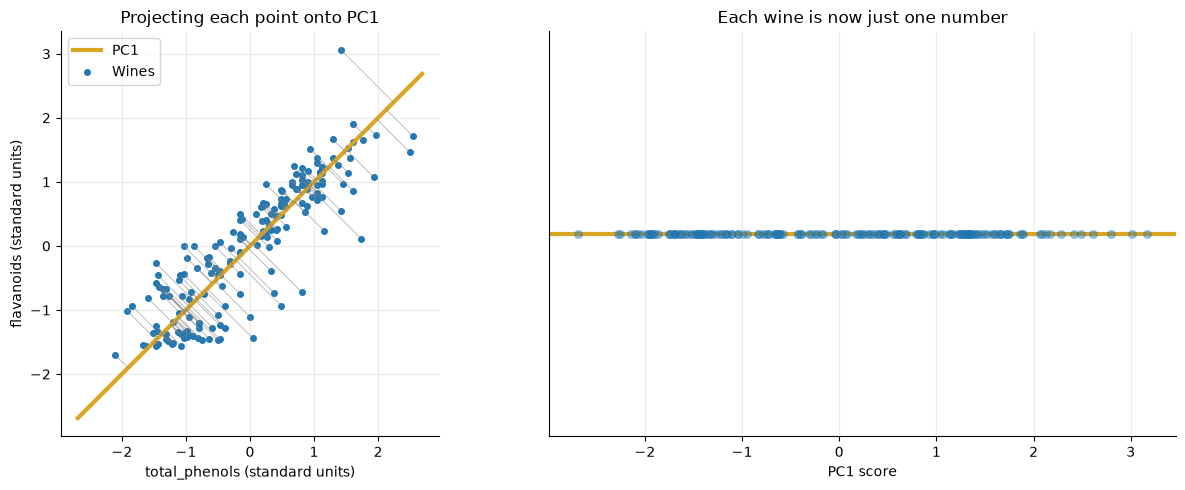

In [16]:
two_features = StandardScaler().fit_transform(wine_X[['total_phenols', 'flavanoids']])

pca_two = PCA(n_components=1)
pc1_scores = pca_two.fit_transform(two_features)        # each wine's position along PC1
projected = pca_two.inverse_transform(pc1_scores)       # where each point lands on the PC1 line

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.1, 1]})
line = np.outer(np.linspace(-3.8, 3.8, 2), pca_two.components_[0])
axes[0].plot(line[:, 0], line[:, 1], color='goldenrod', lw=3, label='PC1')
for (x0, y0), (x1, y1) in zip(two_features, projected):
    axes[0].plot([x0, x1], [y0, y1], color='gray', lw=0.6, alpha=0.6)   # the "slide" onto the line
axes[0].scatter(two_features[:, 0], two_features[:, 1], s=16, label='Wines')
axes[0].set(xlabel='total_phenols (standard units)', ylabel='flavanoids (standard units)', title='Projecting each point onto PC1')
axes[0].set_aspect('equal'); axes[0].legend(loc='upper left')

axes[1].scatter(pc1_scores[:, 0], np.zeros(len(pc1_scores)), s=30, alpha=0.4)
axes[1].axhline(0, color='goldenrod', lw=3, zorder=0)
axes[1].set(yticks=[], ylim=(-1, 1), xlabel='PC1 score', title='Each wine is now just one number')
plt.tight_layout()
plt.show()

The gray lines show how far each point slid to land on PC1. Those distances are the information we lose. Because the cloud is long and thin, they are small, and **most of the variation remains**.

## 4.3 Explained Variance

Each principal component accounts for a share of the dataset's **total variance**. The **explained variance ratio** tells us what fraction each one captures:

In [17]:
print(np.round(PCA().fit(two_features).explained_variance_ratio_, 3))

[0.932 0.068]


PC1 alone captures about **93%** of the variance in these two features. Going from two columns to one only costs us about 7% of the spread.

Now the whole dataset: standardize all 13 features (remember how `proline` dominated K-Means!) and fit PCA. The **cumulative explained variance** tells us how much the first $N$ components keep together.

In [18]:
scaler = StandardScaler()
wine_scaled = scaler.fit_transform(wine_X)

pca = PCA().fit(wine_scaled)
explained = pd.DataFrame({
    'Explained variance ratio': pca.explained_variance_ratio_,
    'Cumulative': np.cumsum(pca.explained_variance_ratio_)
}, index=[f'PC{i}' for i in range(1, 14)])
display(explained.round(3))

,Explained variance ratio,Cumulative
PC1,0.362,0.362
PC2,0.192,0.554
PC3,0.111,0.665
PC4,0.071,0.736
PC5,0.066,0.802
PC6,0.049,0.851
PC7,0.042,0.893
PC8,0.027,0.920
PC9,0.022,0.942
PC10,0.019,0.962


PC1 captures about 36% and PC2 about 19% of the variance, so the first two components keep about **55%** of the information in all 13 features:

<div align="center"><b>PC1 36% + PC2 19% ≈ 55% of the total variance</b></div>

Keeping all 13 components keeps 100%, but then we haven't reduced anything. **More components keep more variance, but reduce less.**

## 4.4 How Many Components?

Plot each component's share alongside the running total (sometimes called a **scree plot**):

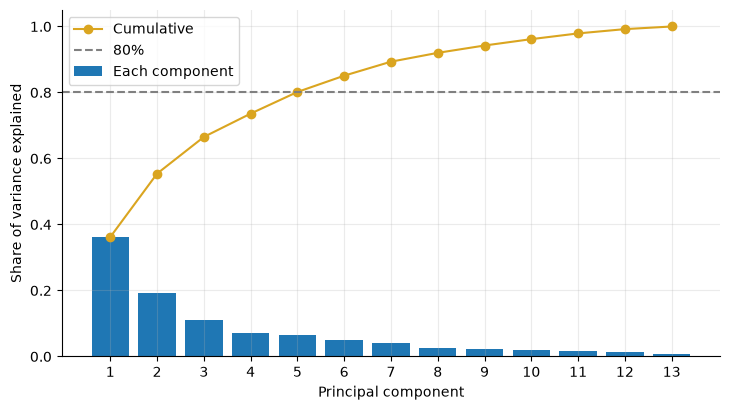

In [19]:
components = np.arange(1, 14)
plt.figure(figsize=(8.5, 4.5))
plt.bar(components, pca.explained_variance_ratio_, label='Each component')
plt.plot(components, np.cumsum(pca.explained_variance_ratio_), 'o-', color='goldenrod', label='Cumulative')
plt.axhline(0.80, color='gray', linestyle='--', lw=1.5, label='80%')
plt.xticks(components)
plt.xlabel('Principal component'); plt.ylabel('Share of variance explained')
plt.legend()
plt.show()

The bars shrink quickly. How many to keep depends on your goal:

* **Preserve enough variance for your goal.** A common rule of thumb is 80–90% of the variance. For the wines, the cumulative line reaches 80% at **5 components**, still much simpler than 13. (Thresholds like 80% are conventions, not laws.)
* **For visualization, two components are convenient**, since that's what fits on a scatter plot, even if they don't capture everything.
* **For downstream modeling, check the effect on actual task performance.** Try a few numbers of components and compare validation scores, just like any other hyperparameter.

## 4.5 Reading the Components

The weights of each component (sometimes called **loadings**) live in `pca.components_`, one row per component and one column per original feature:

In [20]:
loadings = pd.DataFrame(pca.components_[:2], index=['PC1', 'PC2'], columns=wine_X.columns)
display(loadings.T.round(2))

,PC1,PC2
alcohol,0.14,0.48
malic_acid,-0.25,0.22
ash,-0.00,0.32
alcalinity_of_ash,-0.24,-0.01
magnesium,0.14,0.30
total_phenols,0.39,0.07
flavanoids,0.42,-0.00
nonflavanoid_phenols,-0.30,0.03
proanthocyanins,0.31,0.04
color_intensity,-0.09,0.53


A large positive weight pushes a wine's score *up* on that component, a large negative weight pushes it *down*, and a weight near 0 means the feature barely matters.

* **PC1** has large positive weights on `flavanoids`, `total_phenols`, `od280/od315_of_diluted_wines`, and `proanthocyanins`, and negative weights on `nonflavanoid_phenols`, `malic_acid`, and `alcalinity_of_ash`. Roughly: **high PC1 = rich in flavanoids and related phenols.**
* **PC2** is driven by `color_intensity`, `alcohol`, and `proline`. Roughly: **high PC2 = darker, stronger, higher in proline.**

No component is a single original column; each blends many features. (Technical note: the overall sign of a component is arbitrary. Flipping every weight describes the same axis pointing the other way.)

### Pros & Cons — PCA

| Strengths | Weaknesses |
|-----------|------------|
| Compresses many correlated features into a few | Components can be hard to describe in plain language |
| Makes high-dimensional data plottable in 2-D | Linear only: can't "unroll" curved patterns |
| Explained variance tells you exactly how much you kept | Ignores any target: high variance ≠ most predictive |
| Removes redundancy; can speed up later models | Very sensitive to feature scaling |

### Key Parameters — PCA

| Parameter | What it does | Default | Effect of changing it |
|-----------|-------------|---------|----------------------|
| `n_components` | How many components to keep | `None` (keep all) | An integer keeps that many. A number between 0 and 1 (like `0.80`) keeps just enough components to reach that share of the variance |
| `random_state` | Fixes randomness for some solvers | `None` | Any integer makes results reproducible |

> **Rule of thumb:** Standardize first (unless all features share one meaningful unit), fit PCA with all components,
> look at the cumulative explained variance, and then decide how many to keep.

### ✏️ Quick Check

1. PC1 explains 60% of the variance and PC2 explains 25%. How much do the first two components keep together?
2. Why is PC2 always at a right angle to PC1?
3. A PC1 loadings table shows weights of 0.7 on `height` and 0.7 on `weight`, and almost 0 elsewhere. What might PC1 measure?

<details>
<summary><b>Click for answers</b></summary>

1. **85%** (60% + 25%). The remaining 15% is lost if we drop the other components.
2. PC2 must capture *new* spread that PC1 hasn't already captured. Pointing at a right angle guarantees it doesn't repeat PC1's direction.
3. Something like **overall body size**: people who are taller *and* heavier get high PC1 scores.
</details>

---
# Part 5: Using PCA

## 5.1 A Practical Workflow

```
1. Select numeric features and handle missing values   →  PCA needs numbers, with no gaps
2. Fit scaling on training data, transform consistently →  same leakage rules as the Model Evaluation chapter
3. Fit PCA and choose a number of components            →  explained variance + your goal
4. Transform the data into principal-component coordinates
5. Visualize, model, and interpret with care
```

If PCA feeds into a supervised model, put it inside a pipeline, such as `make_pipeline(StandardScaler(), PCA(n_components=5), LogisticRegression())`, so the scaler and PCA learn only from training data. For exploring the wines, we'll fit on all rows. Steps 3 and 4 happen together with `fit_transform`:

In [21]:
pca_2d = PCA(n_components=2)
wine_2d = pca_2d.fit_transform(wine_scaled)

wine_pcs = pd.DataFrame(wine_2d, columns=['PC1', 'PC2'])
display(wine_pcs.head())
print(f"Share of variance kept in 2-D: {pca_2d.explained_variance_ratio_.sum():.1%}")

,PC1,PC2
0,3.316751,1.443463
1,2.209465,-0.333393
2,2.516740,1.031151
3,3.757066,2.756372
4,1.008908,0.869831


Share of variance kept in 2-D: 55.4%


## 5.2 Combining PCA and K-Means 🤝

**PCA reduces the number of features; K-Means groups observations.** There are two common ways to combine them:

| Approach | Steps | Why use it |
|---|---|---|
| **Cluster in the reduced space** | standardize → PCA → K-Means → inspect groups | Faster clustering; can filter out noisy directions |
| **Cluster in the original space, use PCA to visualize** | standardize → K-Means on all features; PCA only for the plot | Clusters use all of the information |

### Demo: Discover Patterns

Let's take the second approach. We already clustered the standardized wines with K-Means in Part 2 (`scaled_labels`). Now we can finally *see* those clusters:

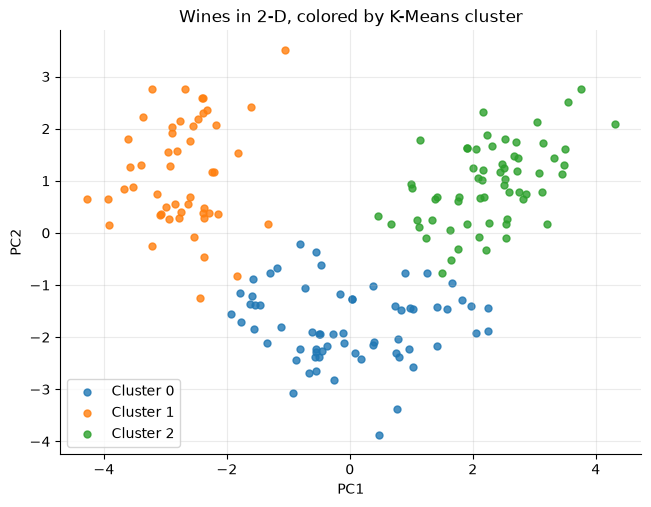

In [22]:
wine_pcs['cluster'] = scaled_labels

plt.figure(figsize=(7.5, 5.5))
for c in sorted(wine_pcs['cluster'].unique()):
    in_cluster = wine_pcs[wine_pcs['cluster'] == c]
    plt.scatter(in_cluster['PC1'], in_cluster['PC2'], s=25, alpha=0.8, label=f'Cluster {c}')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('Wines in 2-D, colored by K-Means cluster'); plt.legend()
plt.show()

The three clusters form three regions. Using the loadings from 4.5, we can describe them: one sits far right on PC1 (rich in flavanoids), one sits low on PC2 (lighter in color, with less alcohol and proline), and one sits far left on PC1 but high on PC2 (low in flavanoids, but dark and intense).

Now for the big reveal. Let's color the same plot by each wine's **true grape variety**, the labels we've been hiding:

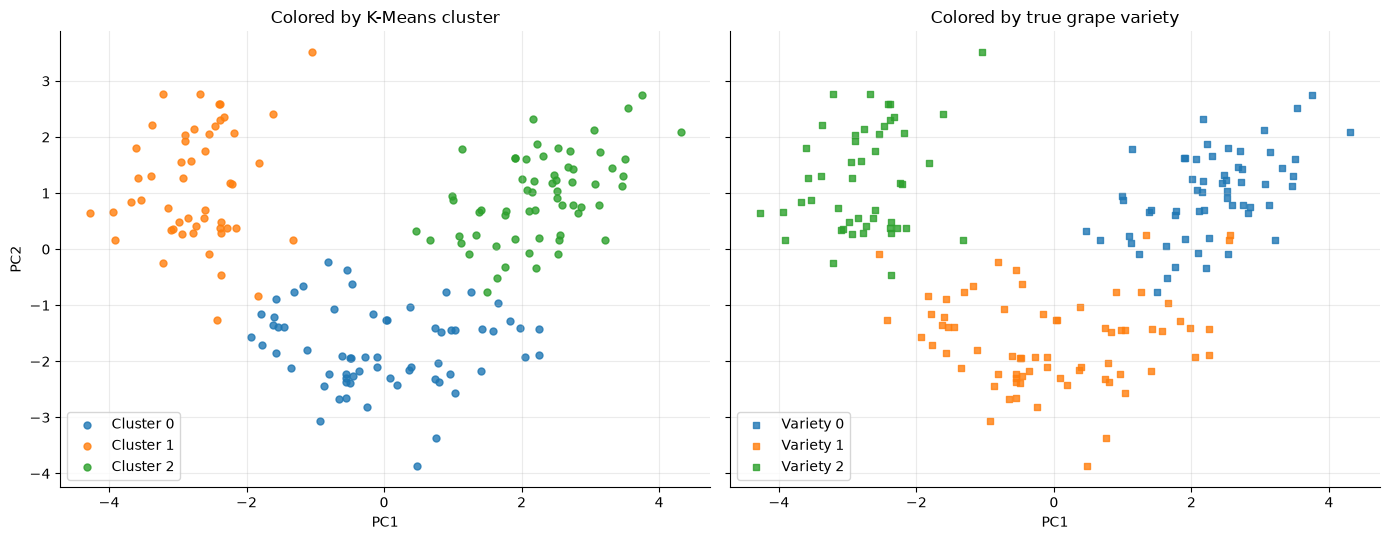

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for c in sorted(wine_pcs['cluster'].unique()):
    in_cluster = wine_pcs[wine_pcs['cluster'] == c]
    axes[0].scatter(in_cluster['PC1'], in_cluster['PC2'], s=25, alpha=0.8, label=f'Cluster {c}')
for v in sorted(wine_variety.unique()):
    in_variety = wine_pcs[wine_variety == v]
    axes[1].scatter(in_variety['PC1'], in_variety['PC2'], s=25, alpha=0.8, marker='s', label=f'Variety {v}')
axes[0].set_title('Colored by K-Means cluster'); axes[1].set_title('Colored by true grape variety')
for ax in axes:
    ax.set_xlabel('PC1'); ax.legend()
axes[0].set_ylabel('PC2')
plt.tight_layout()
plt.show()

The two pictures are nearly identical (the colors are shuffled, since cluster numbers are just name tags). Using only chemistry and two unsupervised techniques, we rediscovered the three grape varieties.

But we should also discuss **what this plot hides**:

* These two components keep only about **55%** of the variance. The other 45% is invisible here.
* Points near a boundary might be well separated in the other 11 dimensions, or might not. This picture can't tell us.
* We got lucky that the real groups differ along the directions of greatest variance. That isn't guaranteed.

> **A clean-looking 2D plot does not guarantee good clusters**, and a messy-looking one doesn't necessarily mean the clusters are bad.

## 5.3 When PCA Can Mislead ⚠️

* **PCA is linear.** Every component is a straight-line axis, so PCA can't uncover every nonlinear pattern (like the crescent moons in 2.7). Nonlinear methods such as t-SNE and UMAP exist for this.
* **Directions with high variance are not always the most predictive.** PCA never looks at a target. The feature that best predicts what you care about could have little variance and end up in a component you drop.
* **Components may be hard to interpret** in plain language.
* **A 2D plot never tells the whole story.** Always check how much variance your plot keeps.
* **Scaling strongly influences the result.** Here is PCA on the wines *without* standardizing:

In [24]:
pca_raw = PCA().fit(wine_X)
display(pd.DataFrame({
    'Explained variance ratio': pca_raw.explained_variance_ratio_[:3],
    'Feature with the largest weight': [wine_X.columns[np.argmax(np.abs(row))] for row in pca_raw.components_[:3]]
}, index=['PC1', 'PC2', 'PC3']).round(4))

,Explained variance ratio,Feature with the largest weight
PC1,0.9981,proline
PC2,0.0017,magnesium
PC3,0.0001,alcalinity_of_ash


Without scaling, PC1 "explains" about 99.8% of the variance. That sounds amazing until you notice PC1 is basically just `proline`, whose numbers are in the hundreds. The result tells us about **units**, not about wine.

### ✏️ Quick Check

1. Your 2-D PCA plot keeps 30% of the variance and shows two clusters overlapping. Can you conclude K-Means failed to separate them?
2. You want to use PCA before a classifier. Why should the scaler and PCA be fit on training data only?
3. A feature has tiny variance but is the single best predictor of your target. What might PCA do to it?

<details>
<summary><b>Click for answers</b></summary>

1. **No.** 70% of the variance isn't shown; the clusters may be well separated in the dimensions you can't see. Check the cluster summaries in the original features.
2. Fitting on all rows lets the test data influence the transformation, which is **data leakage**. Use a pipeline so each step learns only from training data.
3. It may end up in a low-variance component that gets **dropped**, throwing away exactly the information you need. Check task performance, not just explained variance.
</details>

---
# Chapter Summary

Well done making it through the chapter! Here is a full recap:

---

### Unsupervised Learning
* Works with features only, **no target**: it discovers structure instead of predicting answers.
* Two main questions: **clustering** (which rows belong together?) and **dimensionality reduction** (can we use fewer columns?).
* There's no answer key, so judge results by whether they are **useful, stable, and make sense**.

### K-Means Clustering
* **Choose K → assign each point to its nearest centroid → move each centroid to its cluster's mean → repeat** until nothing changes.
* Choose $K$ with the **elbow plot** of inertia, then **interpret** the clusters with feature summaries. Inertia always falls as $K$ grows.
* Random starts can give different answers; `n_init` keeps the best of several runs.
* Built on distances, so **standardize** features with different units.
* Works best on compact, round clusters; sensitive to outliers; cluster numbers have no built-in meaning.

### Dimensionality Reduction
* Each feature is one **dimension**. Reducing dimensions helps visualization and removes overlapping information.
* **Central tradeoff:** fewer dimensions ↔ less detail retained. Keep what matters for the task.
* **Selection** keeps some original columns; **extraction** builds new columns from old ones.

### Principal Component Analysis
* Builds new axes: **PC1** captures the most variance, each later component the most remaining variance at a right angle.
* Each component is a **weighted mix** of the original features (read the loadings in `components_`).
* **Explained variance ratio** = share of variance per component; the **cumulative** total tells you how much you keep.
* Linear, ignores the target, and **very sensitive to scaling**. A 2-D plot never tells the whole story.

| | K-Means | PCA |
|---|---|---|
| **Question** | Which observations belong together? | Can we use fewer features? |
| **What it reduces** | Many **rows** → a few groups | Many **columns** → a few components |
| **Key choice** | Number of clusters, $K$ | Number of components |
| **How we choose** | Elbow plot + interpretation | Explained variance + our goal |
| **Needs scaling?** | Yes, when units differ | Yes, when units differ |

---

### Quick-Reference Code

```python
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# --- K-Means (scale first!) ---
kmeans = make_pipeline(StandardScaler(), KMeans(n_clusters=3, n_init=10, random_state=42)).fit(X)
labels = kmeans[-1].labels_                         # cluster number for each row
kmeans[-1].inertia_                                 # use for the elbow plot

# --- PCA ---
X_scaled = StandardScaler().fit_transform(X)
pca = PCA().fit(X_scaled)
pca.explained_variance_ratio_                       # share of variance per component
np.cumsum(pca.explained_variance_ratio_)            # running total
X_2d = PCA(n_components=2).fit_transform(X_scaled)  # 2 columns, ready to plot
```

### References and Further Reading

For implementation details, see the scikit-learn user guides on [K-Means clustering](https://scikit-learn.org/stable/modules/clustering.html#k-means), [PCA](https://scikit-learn.org/stable/modules/decomposition.html#pca), and [standardization](https://scikit-learn.org/stable/modules/preprocessing.html#standardization-or-mean-removal-and-variance-scaling). The wine data come from the UCI Machine Learning Repository's [Wine dataset](https://archive.ics.uci.edu/dataset/109/wine), included in scikit-learn as `load_wine`. The gym dataset is fictional.